In [1]:
import sys
import os

# Ensure local packages (models, lib_QEC) are importable
for p in [os.path.abspath(".." ), os.path.abspath(".")]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer import AerSimulator

from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

import matplotlib.pyplot as plt

# for classical comparison
from scipy.linalg import expm
from scipy.integrate import solve_ivp

# Import Lipkin model
from models.Lipkin import diabolic_points, qpt_line, LipkinHamiltonian
# from models.Lipkin_spin import build_lipkin_hamiltonian, lipkin_ground_state, lipkin_spectrum

# LaTeX-friendly plot settings (consistent with standard document formatting)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

In [2]:
# Simulate measurement noise on the energy basis projections
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer.noise import NoiseModel

# Get backend from real device (or fallback to local FakeAachen if offline/no credentials)
try:
    service = QiskitRuntimeService()
    backend = service.backend("ibm_aachen")
    print(f"Connected to IBM Quantum. Using backend: {backend.name}")
except Exception as e:
    from qiskit_ibm_runtime.fake_provider import FakeAachen
    backend = FakeAachen()
    print(f"IBM Quantum credentials not found ({e}). Falling back to local {backend.name}.")


Using noise model from: ibm_aachen


# Parameters

In [3]:
# Lipkin model parameters
N = 5 # system size

# Time evolution
x0, y0 = -0.5, 0.0 # initial point
xf, yf = -0.3, 1.5 # final point
T = 10.0            # final driving time
n_steps = 20        # steps in time
trotter_order = 1  # used in SuzukiTrotter decomposition on QC

# Quantum Computer transpilation
qc_optimization_level = 3  # optimization level for transpilation on QC
layout_method='sabre'  # 'trivial', 'dense', and 'sabre'
routing_method='sabre' # 'basic', 'lookahead', 'sabre'
translation_method='default' # sometimes does not work
approximation_degree = 1.   # 1.0=no approximation, 0.0=maximal approximation - below 1. it totally destroys noisy simulation

# Qiskit Estimator
number_of_shots = 4000
enable_dd = False             # Dynamical Decoupling (often False for dense circuits)
enable_twirling = True        # Pauli Twirling (good for error suppression)

# option to run on quantum backend
run_on_quantum_backend = True # just so we can run the full notebook at once for testing
rerun_continuous_simulation = True # just to make the execution faster

# Aer simulator
aer_optimization_level = qc_optimization_level  # keep the same as for QC transpilation
number_of_shots_aer = number_of_shots

## Path Definition in (x,y) Parameter Space

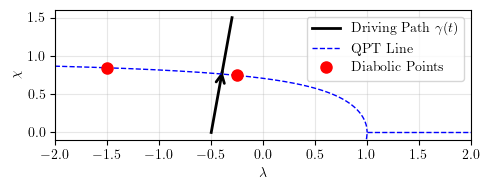

In [4]:
from matplotlib.patches import FancyArrowPatch
def gamma(t, T):
    """Define the driving path gamma(t) in (x,y) parameter space."""
    # Linear path from x0, y0 to xf, yf
    x = x0 + (xf - x0) * t / T
    y = y0 + (yf - y0) * t / T
    
    return x, y

ts = np.linspace(0, T, 100)
xs, ys = zip(*[gamma(t, T) for t in ts])

fig, ax = plt.subplots(figsize=(5, 2))

# Plot driving path
ax.plot(xs, ys, 'k-', linewidth=2, label=r'Driving Path $\gamma(t)$')

# Add arrow using FancyArrowPatch for proper scaling independent of aspect ratio
arrow_idx = len(xs) // 2
arrow = FancyArrowPatch((xs[arrow_idx], ys[arrow_idx]), (xs[arrow_idx+5], ys[arrow_idx+5]),
                         arrowstyle='->', mutation_scale=15, color='k', lw=2)
ax.add_patch(arrow)

# Plot QPT line (curved part)
lambda_vals = np.linspace(-10, 0.999999, 2000)
chi_vals = qpt_line(lambda_vals)
ax.plot(lambda_vals, chi_vals, 'b--', linewidth=1, label=r'QPT Line')
ax.plot(lambda_vals, -chi_vals, 'b--', linewidth=1)
ax.plot([1, 2.5], [0, 0], 'b--', linewidth=1)

# Plot diabolic points
dp = diabolic_points(N)
ax.plot(dp[:, 0], dp[:, 1], 'ro', markersize=8, label=r'Diabolic Points')

ax.set_xlabel(r'$\lambda$')
ax.set_ylabel(r'$\chi$')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(-2, 2)
ax.set_ylim(-0.1, 1.6)
plt.tight_layout()
# plt.show()
plt.savefig('driving_path_N=5.pdf')

## Hamiltonian definition

#### Version with N+1 dim Hamiltonian with j=N/2:

In [5]:
dim_H = N + 1  # Number of physical states in the j=N/2 sector
num_qubits = int(np.ceil(np.log2(dim_H)))

def lipkin_in_time(t: float, T: float, atol: float = 1e-10) -> SparsePauliOp:
    """Build Lipkin Hamiltonian as SparsePauliOp with proper padding to 2^n dimension."""
    x, y = gamma(t, T)
    H_physical = LipkinHamiltonian(N, λ=x, χ=y)
    
    # Pad to 2^n for quantum circuit compatibility
    dim = N + 1
    padded_dim = 2**num_qubits
    H_padded = np.zeros((padded_dim, padded_dim), dtype=complex)
    H_padded[:dim, :dim] = H_physical
    
    # Add large energy offset to non-physical states
    # This keeps them out of the low-energy subspace
    E_max = np.max(np.diag(H_physical.real))  # Maximum physical energy
    offset = E_max + 1e10  # Large energy gap
    for i in range(dim, padded_dim):
        H_padded[i, i] = offset
    
    return SparsePauliOp.from_operator(Operator(H_padded)).simplify(atol=atol)

print(f'Lipkin model: N = {N}')
print(f'Hilbert space dimension (physical): {dim_H}')
print(f'Number of qubits: {num_qubits}')
print(f'Padded dimension: {2**num_qubits}')
print(f'Number of terms in Hamiltonian at t=0: {len(lipkin_in_time(0, T, atol=1e-10))}')

Lipkin model: N = 5
Hilbert space dimension (physical): 6
Number of qubits: 3
Padded dimension: 8
Number of terms in Hamiltonian at t=0: 16


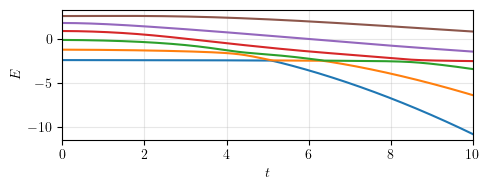

In [7]:
# Spectrum along the path with CORRECTED padding
n_points = 500
t_values = np.linspace(0, T, n_points)
eigenvalues_along_path = np.zeros((n_points, dim_H))

for i, t in enumerate(t_values):
    H = lipkin_in_time(t, T).to_matrix()
    evals = np.linalg.eigvalsh(H)
    eigenvalues_along_path[i, :] = evals[:dim_H]  # Only physical states

fig, ax = plt.subplots(figsize=(5, 2))
for j in range(dim_H):
    ax.plot(t_values, eigenvalues_along_path[:, j], label=rf'$E_{{{j}}}$')

ax.set_xlabel(r'$t$')
ax.set_ylabel(r'$E$')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, T)
# ax.legend()
plt.tight_layout()
plt.savefig('driving_path_N=5_spectrum.pdf')

## Time evolution circuit

Uses statevector simulation to preserve full quantum information, then project onto energy eigenbasis.

- Usually we start from some easily preparable state, so the first step would be ommitted. Here the initial state is set to be the ground state of $H(0)$, so we have the freedom. But it is cheating.
- Classical diagonalization is also used at the final time, this could be replaced by quantum state tomography to do the computation fully on QC. However, practically computational basis is good enough for many practical applications, here we just want to intuitively understand the result. Or we would measure in the end some observable (like total magnetization).

At final time we have $|\psi\rangle = \sum_i c_i |E_i\rangle$ in the energy basis, for $c_i = \langle E_i|\psi\rangle$.

In matrix form: $c = \text{evecsf}^\dagger \psi$ (where $\psi$ is in the computational basis).

So $U^\dagger = \text{evecsf}^\dagger$ transforms from the computational to the energy basis. After applying $U^\dagger$ and measuring $|i\rangle$, we get probability $|c_i|^2$.

### Create the circuit with initial position and Trotterization

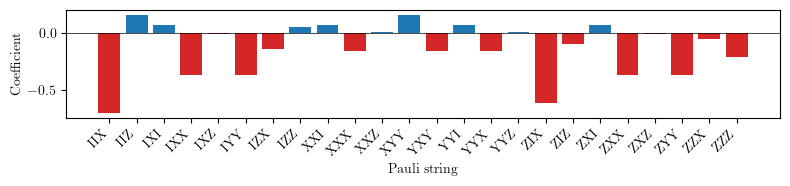

In [309]:
# Visualize Hamiltonian Pauli decomposition
H_vis = lipkin_in_time(0.5*T, T)
coeffs = H_vis.coeffs.real
paulis = [str(p) for p in H_vis.paulis]

# Filter out large padding terms for better visualization
mask = np.abs(coeffs) < 1e6
coeffs_filtered = coeffs[mask]
paulis_filtered = [p for p, m in zip(paulis, mask) if m]

fig, ax = plt.subplots(figsize=(8, 2))
colors = ['#1f77b4' if c >= 0 else '#d62728' for c in coeffs_filtered]
ax.bar(paulis_filtered, coeffs_filtered, color=colors)
ax.set_ylabel(r'Coefficient')
ax.set_xlabel(r'Pauli string')
plt.xticks(rotation=45, ha='right')
ax.axhline(0, color='k', linewidth=0.5)
plt.tight_layout()
plt.savefig("midTime_Hamiltonian_N=5.pdf")

In [310]:
# Count terms in Hamiltonian and how many were filtered out
H = lipkin_in_time(0.5*T, T)
coeffs = H.coeffs.real
total_terms = len(coeffs)
terms_kept = np.sum(np.abs(coeffs) < 1e9)
terms_ignored = total_terms - terms_kept

print(f"Total terms in Hamiltonian: {total_terms}")
print(f"Terms shown (|coeff| < 1e6): {terms_kept}")
print(f"Terms ignored (padding terms with |coeff| >= 1e6): {terms_ignored}")

Total terms in Hamiltonian: 28
Terms shown (|coeff| < 1e6): 24
Terms ignored (padding terms with |coeff| >= 1e6): 4


In [311]:
def quantum_state_driving(T: float, n_steps: int) -> QuantumCircuit:
    dt = T / n_steps
    qc = QuantumCircuit(num_qubits)

    # Initialize to ground state at t=0
    H0_matrix = lipkin_in_time(0.0, T)
    _, evecs0 = np.linalg.eigh(H0_matrix)
    qc.initialize(evecs0[:, 0], range(num_qubits))
    qc.barrier(label=r'$|\psi_0\rangle$')
    
    for step in range(n_steps):
        t = (step + 0.5) * dt
        H_pauli = lipkin_in_time(t, T)
        evo_gate = PauliEvolutionGate(H_pauli, time=dt, synthesis=SuzukiTrotter(order=trotter_order))
        qc.append(evo_gate, range(num_qubits))
    
    qc.barrier(label=r'$|\psi(T)\rangle$')
    return qc

Single time step visualization:

Circuit summary (with initial state preparation):
  Qubits: 3
  Gates: 119
  Depth: 90

Trotter step only (without initial state preparation):
  Gates: 115
  Depth: 88


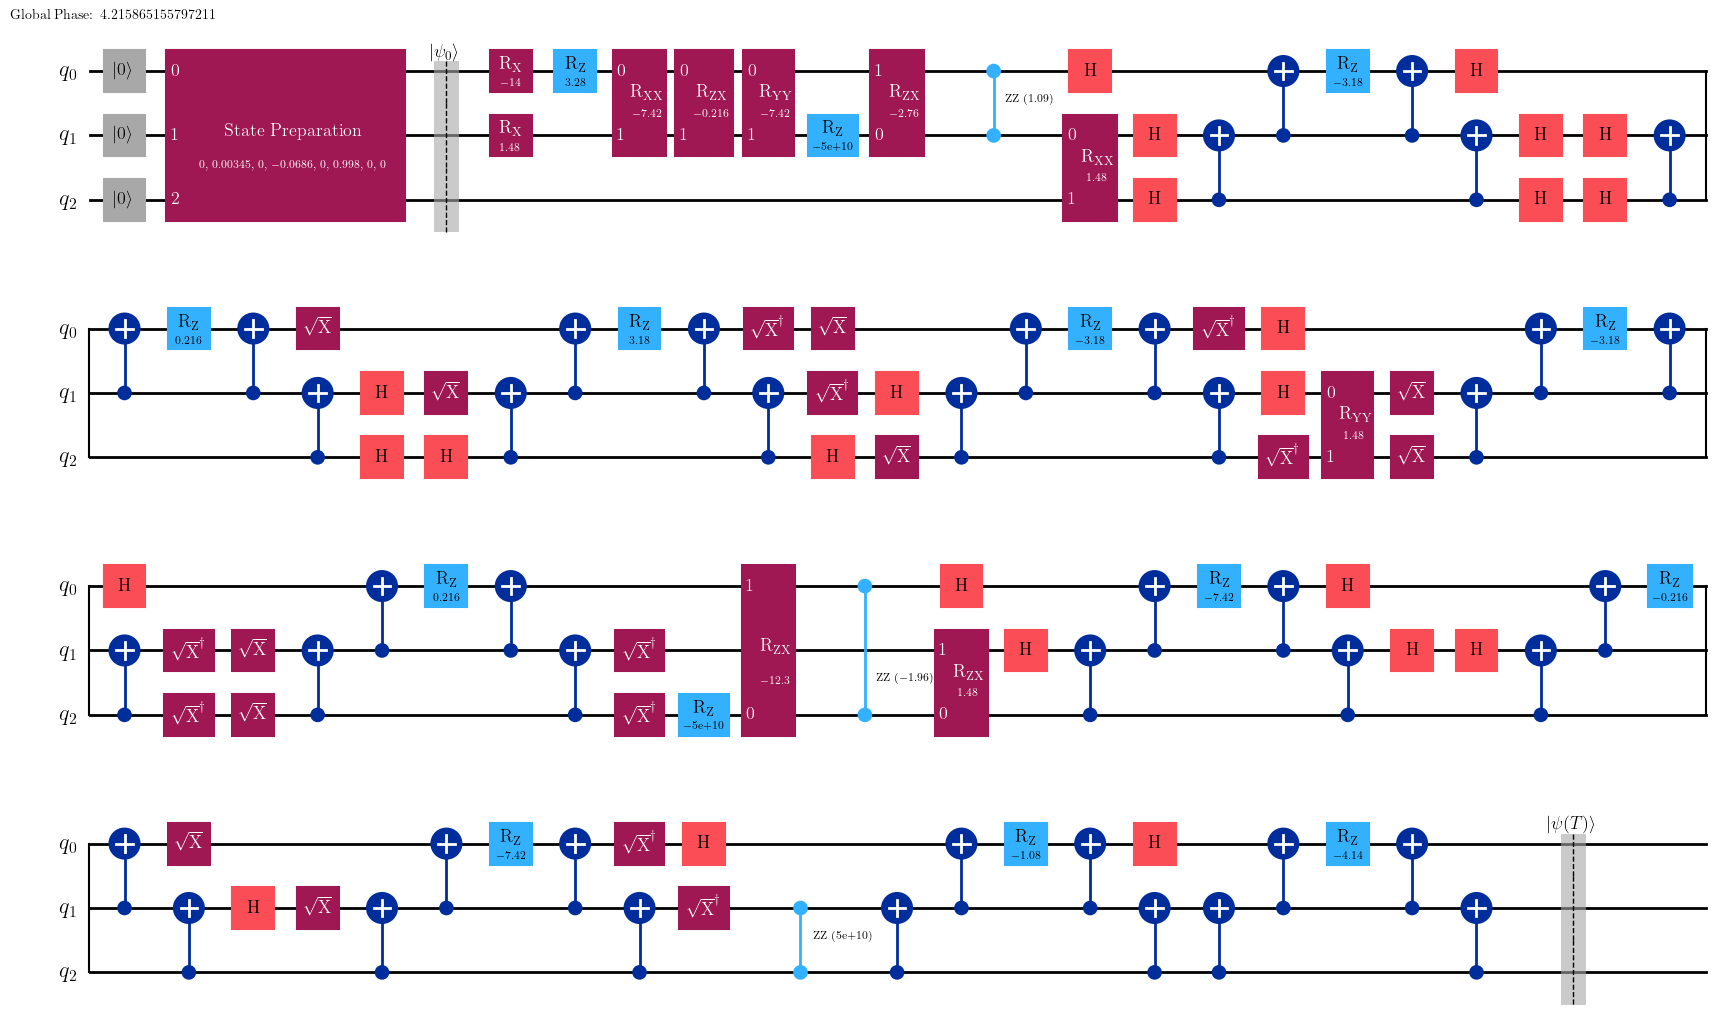

In [312]:
qc1 = quantum_state_driving(T=T, n_steps=1)

print(f"Circuit summary (with initial state preparation):")
print(f"  Qubits: {qc1.num_qubits}")
print(f"  Gates: {qc1.decompose().size()}")
print(f"  Depth: {qc1.decompose().depth()}")

# Create a circuit with just the Trotter step (no initialization)
qc_trotter_only = QuantumCircuit(num_qubits)
dt = T / 1  # single step
t = 0.5 * dt  # midpoint
H_pauli = lipkin_in_time(t, T)
evo_gate = PauliEvolutionGate(H_pauli, time=dt, synthesis=SuzukiTrotter(order=trotter_order))
qc_trotter_only.append(evo_gate, range(num_qubits))

print(f"\nTrotter step only (without initial state preparation):")
print(f"  Gates: {qc_trotter_only.decompose().size()}")
print(f"  Depth: {qc_trotter_only.decompose().depth()}")

      
# Draw circuit and save as PDF (LaTeX-friendly)
fig = qc1.decompose().draw('mpl')
fig.savefig('gates_single_step_evolution_N=5.pdf', bbox_inches='tight')
fig

Single-step transpiled circuit:
  Qubits: 156
  Gates: 238
  Depth: 144


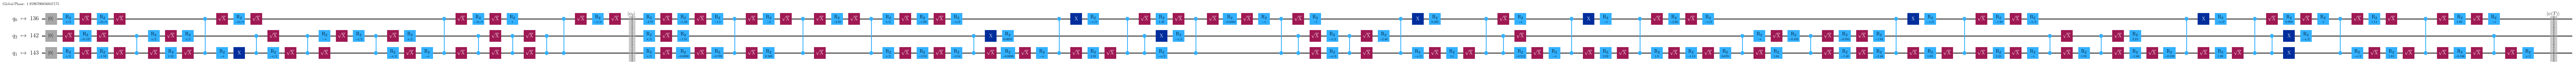

In [313]:
# Transpile single-step circuit to backend and display
pm_single = generate_preset_pass_manager(
    backend=backend,
    optimization_level=qc_optimization_level,
    layout_method=layout_method,
    routing_method=routing_method,
    translation_method=translation_method,
    approximation_degree=approximation_degree
)
qc1_transpiled = pm_single.run(qc1)

print(f"Single-step transpiled circuit:")
print(f"  Qubits: {qc1_transpiled.num_qubits}")
print(f"  Gates: {qc1_transpiled.size()}")
print(f"  Depth: {qc1_transpiled.depth()}")

qc1_transpiled.draw('mpl', fold=-1)

Full time evolution:

Circuit summary:
  Qubits: 3
  Depth: 1743
  Gates: 2304




In [314]:
qc = quantum_state_driving(T=T, n_steps=n_steps)

print(f"Circuit summary:")
print(f"  Qubits: {qc.num_qubits}")
print(f"  Depth: {qc.decompose().depth()}")
print(f"  Gates: {qc.decompose().size()}")

qc.draw('mpl', fold=-1)


### Get the final Hamiltonian and its eigenbasis

In [315]:
# Get final Hamiltonian eigenbasis
Hf = lipkin_in_time(T, T)
evalsf, evecsf = np.linalg.eigh(Hf.to_matrix())

print(f"Physical eigenvalues at T={T}:")
for i, ev in enumerate(evalsf[:dim_H]):
    print(f"  E_{i} = {ev:.6f}")

Physical eigenvalues at T=10.0:
  E_0 = -10.841926
  E_1 = -6.395021
  E_2 = -3.412375
  E_3 = -2.501314
  E_4 = -1.419394
  E_5 = 0.870029


In [316]:
def create_projector_observables(evecsf, n_qubits, n_states):
    """
    Create projector observables |E_k⟩⟨E_k| as SparsePauliOp for each eigenstate.
    
    Args:
        evecsf: Eigenvectors of final Hamiltonian (columns are |E_k⟩)
        n_qubits: Number of qubits in circuit
        n_states: Number of states to create projectors for
        
    Returns:
        projectors: List of SparsePauliOp projectors
    """
    projectors = []
    
    for k in range(n_states):
        # Get k-th eigenvector
        E_k = evecsf[:, k]
        
        # Create projector matrix |E_k⟩⟨E_k|
        projector_matrix = np.outer(E_k, E_k.conj())
        
        # Convert to SparsePauliOp
        projector_pauli = SparsePauliOp.from_operator(
            Operator(projector_matrix)
        ).simplify(atol=1e-10)
        
        projectors.append(projector_pauli)
    
    return projectors

projectors = create_projector_observables(evecsf, num_qubits, dim_H)
print(f"Created {len(projectors)} projector observables for energy eigenstates")

Created 6 projector observables for energy eigenstates


## Transpile and run on backend

In [317]:
# Transpile circuit for the specific backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=qc_optimization_level
                                      ,layout_method=layout_method
                                      ,routing_method=routing_method
                                      ,translation_method=translation_method
                                      ,approximation_degree=approximation_degree
                                  )
qc_transpiled = pm.run(qc)
print(f"Transpiled circuit: {qc_transpiled.size()} gates, depth {qc_transpiled.depth()}")
print(f"Transpiled circuit qubits: {qc_transpiled.num_qubits}")

# Map observables to the transpiled circuit's qubit layout
# The layout tells us which physical qubits our logical qubits were mapped to
layout = qc_transpiled.layout
projectors_mapped = [obs.apply_layout(layout, num_qubits=qc_transpiled.num_qubits) for obs in projectors]
print(f"Mapped observables to {qc_transpiled.num_qubits} qubits using circuit layout")

Transpiled circuit: 3342 gates, depth 2109
Transpiled circuit qubits: 156
Mapped observables to 156 qubits using circuit layout


In [318]:
# Configure Estimator with Error Mitigation
estimator = Estimator(backend)

# Set resilience level for error mitigation
# Level 0: No mitigation
# Level 1: TREX (measurement error mitigation)
# Level 2: ZNE (zero-noise extrapolation) + TREX + twirling
resilience_level = 2 # does not influence the runtime
estimator.options.resilience_level = resilience_level  # type: ignore (because pylance marks this as error)

# Additional options for best results
estimator.options.dynamical_decoupling.enable = enable_dd  # type: ignore
estimator.options.dynamical_decoupling.sequence_type = "XY4"  # type: ignore
estimator.options.twirling.enable_gates = enable_twirling  # type: ignore
estimator.options.default_shots = number_of_shots  # type: ignore

In [319]:
# Run Estimator - one PUB with all observables (using mapped observables)
# Each projector ⟨ψ|E_k⟩⟨E_k|ψ⟩ = |⟨E_k|ψ⟩|² gives the probability
if run_on_quantum_backend:
    pub = (qc_transpiled, projectors_mapped)

    job = estimator.run([pub])
    print(f"Job submitted: {job.job_id()}")
    result = job.result()

    # Extract results
    pub_result = result[0]
    energy_probs_raw = pub_result.data.evs  # Expectation values = probabilities
    std_errors = pub_result.data.stds       # Standard errors

    print(f"\nRaw expectation values (probabilities):")
    for k, (ev, std) in enumerate(zip(energy_probs_raw, std_errors)):
        print(f"  P(E_{k}) = {ev:.4f} ± {std:.4f}")
else:
    print("Skipping quantum backend execution.")

Job submitted: d4tb9nba6tsc73fe6nr0

Raw expectation values (probabilities):
  P(E_0) = 0.1188 ± 0.0123
  P(E_1) = 0.1312 ± 0.0168
  P(E_2) = 0.1155 ± 0.0187
  P(E_3) = 0.1159 ± 0.0286
  P(E_4) = 0.1653 ± 0.0599
  P(E_5) = 0.1082 ± 0.0339


In [320]:
# Process Estimator results: expectation values are the probabilities
# Clip to valid probability range (small negatives from noise)
if run_on_quantum_backend:
    energy_probs_quantum = np.clip(energy_probs_raw, 0, 1)

    # Normalize (should sum to ~1 for physical states)
    total_prob = np.sum(energy_probs_quantum)
    if total_prob > 0:
        energy_probs_quantum = energy_probs_quantum / total_prob

    print("Energy eigenstate populations (from Estimator with error mitigation):")
    for i, (prob, std) in enumerate(zip(energy_probs_quantum, std_errors)):
        print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f} ± {std:.4f}")

    # Expected energy
    expected_E = np.sum(evalsf[:dim_H] * energy_probs_quantum)
    ground_E = evalsf[0]
    print(f"\n⟨E⟩ = {expected_E:.4f}")
    print(f"E_0 = {ground_E:.4f}")
    print(f"Excitation: ⟨E⟩ - E_0 = {expected_E - ground_E:.4f}")
else:
    print("Skipping quantum backend execution.")

Energy eigenstate populations (from Estimator with error mitigation):
  E_0 (E=-10.8419): 0.1574 ± 0.0123
  E_1 (E=-6.3950): 0.1738 ± 0.0168
  E_2 (E=-3.4124): 0.1530 ± 0.0187
  E_3 (E=-2.5013): 0.1536 ± 0.0286
  E_4 (E=-1.4194): 0.2189 ± 0.0599
  E_5 (E=0.8700): 0.1433 ± 0.0339

⟨E⟩ = -3.9101
E_0 = -10.8419
Excitation: ⟨E⟩ - E_0 = 6.9319


### Aer Simulator (noiseless quantum simulation)

In [321]:
# Aer Simulator without noise - simulates the circuit with sampling (like real QC but no noise)
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

# Use an ideal Aer simulator backend (no noise)
aer_noiseless = AerSimulator(method='statevector', seed_simulator=42)

# Create Aer Estimator (no noise) that uses the same transpiled circuit and layout as the real backend
aer_estimator = AerEstimator.from_backend(aer_noiseless)
aer_estimator.options.default_shots = number_of_shots_aer  # type: ignore

# IMPORTANT: Reuse qc_transpiled and projectors_mapped so that Aer simulates the exact circuit and measurement mapping
pub_aer = (qc_transpiled, projectors_mapped)
job_aer = aer_estimator.run([pub_aer])
result_aer = job_aer.result()

# Extract results
aer_evs = result_aer[0].data.evs    # type: ignore
aer_stds = result_aer[0].data.stds  # type: ignore

# Clip and normalize (same processing as quantum backend)
aer_probs_raw = np.clip(aer_evs, 0, 1)
aer_prob_sum = np.sum(aer_probs_raw)
if aer_prob_sum > 0:
    aer_probs_normalized = aer_probs_raw / aer_prob_sum
else:
    aer_probs_normalized = aer_probs_raw

print(f"Aer Simulator (noiseless Estimator, {number_of_shots_aer} shots):")
for i, (prob, std) in enumerate(zip(aer_probs_normalized, aer_stds)):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f} ± {std:.4f}")

# For leakage tracking, we'd need to add a projector onto non-physical space
aer_probs = aer_probs_normalized  # Keep variable name for compatibility

Aer Simulator (noiseless Estimator, 4000 shots):
  E_0 (E=-10.8419): 0.1888 ± 0.0000
  E_1 (E=-6.3950): 0.1348 ± 0.0000
  E_2 (E=-3.4124): 0.1198 ± 0.0000
  E_3 (E=-2.5013): 0.2208 ± 0.0000
  E_4 (E=-1.4194): 0.1854 ± 0.0000
  E_5 (E=0.8700): 0.1504 ± 0.0000


In [322]:
# # Aer Simulator without noise - simulates the circuit with sampling (like real QC but no noise)
# from qiskit_aer import AerSimulator
# from qiskit_aer.primitives import EstimatorV2 as AerEstimator

# aer_noiseless = AerSimulator(method='statevector', seed_simulator=42)

# # Create Aer Estimator (no noise)
# aer_estimator = AerEstimator.from_backend(aer_noiseless)
# aer_estimator.options.default_shots = number_of_shots_aer  # type: ignore

# # Transpile circuit using the SAME backend pass manager to mirror real hardware, this is without error mitigation
# pm_aer = generate_preset_pass_manager(backend=aer_noiseless,optimization_level=qc_optimization_level
#                                       ,layout_method=layout_method
#                                       ,routing_method=routing_method
#                                       ,translation_method=translation_method
#                                       ,approximation_degree=approximation_degree
#                                   )
# qc_aer_transpiled = pm_aer.run(qc)

# # Run with same projector observables (not layout-mapped since Aer doesn't remap)
# pub_aer = (qc_aer_transpiled, projectors)
# job_aer = aer_estimator.run([pub_aer])
# result_aer = job_aer.result()

# # Extract results
# aer_evs = result_aer[0].data.evs
# aer_stds = result_aer[0].data.stds

# # Clip and normalize (same processing as quantum backend)
# aer_probs_raw = np.clip(aer_evs, 0, 1)
# aer_prob_sum = np.sum(aer_probs_raw)
# if aer_prob_sum > 0:
#     aer_probs_normalized = aer_probs_raw / aer_prob_sum
# else:
#     aer_probs_normalized = aer_probs_raw

# print(f"Aer Simulator (noiseless Estimator, {number_of_shots_aer} shots):")
# for i, (prob, std) in enumerate(zip(aer_probs_normalized, aer_stds)):
#     print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f} ± {std:.4f}")

# # For leakage tracking, we'd need to add a projector onto non-physical space
# aer_probs = aer_probs_normalized  # Keep variable name for compatibility

### Aer Simulator with device noise model

In [323]:
# Aer Simulator WITH noise from the real device - using Estimator approach
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

# Create noisy Aer simulator directly from backend to ensure all properties (Target, coupling, etc.) are captured
# This is more robust than manually constructing with noise_model and coupling_map
aer_noisy = AerSimulator.from_backend(backend)

# Create Aer Estimator with the noisy simulator
aer_estimator_noisy = AerEstimator.from_backend(aer_noisy)
aer_estimator_noisy.options.default_shots = number_of_shots_aer  # type: ignore

# IMPORTANT: Reuse the same transpiled circuit and mapped projectors as for the real backend
# so that the noisy Aer simulation faithfully mirrors hardware execution.
pub_aer_noisy = (qc_transpiled, projectors_mapped)
job_aer_noisy = aer_estimator_noisy.run([pub_aer_noisy])
result_aer_noisy = job_aer_noisy.result()

# Extract results
aer_noisy_evs = result_aer_noisy[0].data.evs   # type: ignore
aer_noisy_stds = result_aer_noisy[0].data.stds # type: ignore

# Clip and normalize (same processing as quantum backend)
aer_noisy_probs_raw = np.clip(aer_noisy_evs, 0, 1)
aer_noisy_prob_sum = np.sum(aer_noisy_probs_raw)
if aer_noisy_prob_sum > 0:
    aer_noisy_probs_normalized = aer_noisy_probs_raw / aer_noisy_prob_sum
else:
    aer_noisy_probs_normalized = aer_noisy_probs_raw

print(f"Aer Simulator (with {backend.name} noise, Estimator, {number_of_shots_aer} shots):")
for i, (prob, std) in enumerate(zip(aer_noisy_probs_normalized, aer_noisy_stds)):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f} ± {std:.4f}")

# Store for compatibility
aer_noisy_probs = aer_noisy_probs_normalized

Aer Simulator (with ibm_aachen noise, Estimator, 4000 shots):
  E_0 (E=-10.8419): 0.1666 ± 0.0000
  E_1 (E=-6.3950): 0.1666 ± 0.0000
  E_2 (E=-3.4124): 0.1665 ± 0.0000
  E_3 (E=-2.5013): 0.1669 ± 0.0000
  E_4 (E=-1.4194): 0.1667 ± 0.0000
  E_5 (E=0.8700): 0.1666 ± 0.0000


### Classical simulation of discretized evolution
Does not suffer from Trotterization error, since each step is performed using exact $U(dt)$ step (number of steps is the same `n_steps`) which uses constant Hamiltonian at midpoint of that time step. This simulates "ideal Trotterization" where each time step uses the exact matrix exponential $exp(-i H(t_{mid}) dt)$, but the Hamiltonian is treated as constant during each interval. No Trotter decomposition error, but still has discretization error from piecewise-constant approximation.

In [325]:
# Get initial ground state in physical space
x0_init, y0_init = gamma(0.0, T)
H0_physical = LipkinHamiltonian(N, λ=x0_init, χ=y0_init)
_, evecs0_physical = np.linalg.eigh(H0_physical)
psi_piecewise = evecs0_physical[:, 0].copy()

dt = T / n_steps

# Evolve using piecewise-constant Hamiltonians (exact exp at each step)
for step in range(n_steps):
    # Evaluate Hamiltonian at midpoint of interval (same as Trotter circuit)
    t_mid = (step + 0.5) * dt
    lam_t, chi_t = gamma(t_mid, T)
    H_t = LipkinHamiltonian(N, λ=lam_t, χ=chi_t)
    
    # Exact unitary evolution for this step
    U_step = expm(-1j * H_t * dt)
    psi_piecewise = U_step @ psi_piecewise

# Get final Hamiltonian eigenbasis (physical, not padded)
xf_final, yf_final = gamma(T, T)
Hf_physical = LipkinHamiltonian(N, λ=xf_final, χ=yf_final)
evalsf_physical, evecsf_physical = np.linalg.eigh(Hf_physical)

# Project onto energy eigenbasis of H(T)
piecewise_energy_amps = evecsf_physical.conj().T @ psi_piecewise
piecewise_probs = np.abs(piecewise_energy_amps)**2

print(f"Classical piecewise-constant simulation (exact exp(-iH dt) per step):")
print(f"  n_steps={n_steps}, dt={dt:.4f}")
for i, prob in enumerate(piecewise_probs):
    print(f"  E_{i} (E={evalsf_physical[i]:.4f}): {prob:.4f}")

Classical piecewise-constant simulation (exact exp(-iH dt) per step):
  n_steps=20, dt=0.5000
  E_0 (E=-10.8419): 0.0036
  E_1 (E=-6.3950): 0.0040
  E_2 (E=-3.4124): 0.1479
  E_3 (E=-2.5013): 0.8396
  E_4 (E=-1.4194): 0.0048
  E_5 (E=0.8700): 0.0000


### Exact classical simulation (high precision using solve_ivp)

In [326]:
if rerun_continuous_simulation:
    def classical_continuous(T, psi0):
        """Solve Schrödinger equation continuously using adaptive RK45."""
        def rhs(t, psi_real_imag):
            # Split real and imaginary parts for real-valued ODE solver
            n = len(psi_real_imag) // 2
            psi = psi_real_imag[:n] + 1j * psi_real_imag[n:]
            H = LipkinHamiltonian(N, *gamma(t, T))
            dpsi = -1j * H @ psi
            return np.concatenate([dpsi.real, dpsi.imag])
        
        # Initial condition: split into real and imaginary parts
        y0 = np.concatenate([psi0.real, psi0.imag])
        
        sol = solve_ivp(rhs, (0, T), y0, method='RK45', rtol=1e-10, atol=1e-12)
        
        # Reconstruct complex state
        n = len(psi0)
        psi_final = sol.y[:n, -1] + 1j * sol.y[n:, -1]
        return psi_final

    # Get initial state
    H0 = LipkinHamiltonian(N, *gamma(0.0, T))
    _, evecs0 = np.linalg.eigh(H0)

    psi_precise = classical_continuous(T, evecs0[:, 0])

    # get final state
    H_final = LipkinHamiltonian(N, *gamma(T, T))
    evalsf, evecsf = np.linalg.eigh(H_final)

    # Project onto energy eigenbasis of H(T) using full eigenvectors
    energy_amplitudes_precise = evecsf.conj().T @ psi_precise
    classical_probs_precise_full = np.abs(energy_amplitudes_precise)**2
    classical_probs_precise = classical_probs_precise_full[:dim_H]

    print(f"Exact classical simulation (RK45, high precision):")
    for i, prob in enumerate(classical_probs_precise):
        print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

Exact classical simulation (RK45, high precision):
  E_0 (E=-10.8419): 0.0037
  E_1 (E=-6.3950): 0.0040
  E_2 (E=-3.4124): 0.1459
  E_3 (E=-2.5013): 0.8411
  E_4 (E=-1.4194): 0.0052
  E_5 (E=0.8700): 0.0000


# Final comparison

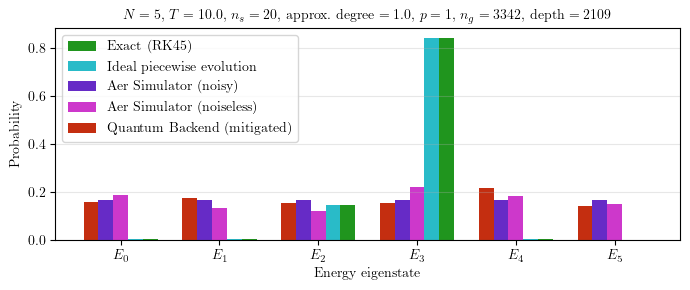

In [331]:
# Comparison plot: Real Hardware vs Aer (noisy) vs Aer (noiseless) vs Trotter (ideal) vs Precise
fig, ax = plt.subplots(figsize=(7, 3))

x_pos = np.arange(dim_H)
width = 0.15

ax.bar(x_pos + 2*width, classical_probs_precise, width, label=r'Exact (RK45)', color="#20951e")
ax.bar(x_pos + 1*width, piecewise_probs, width, label=r'Ideal piecewise evolution', color="#29bbc8")
ax.bar(x_pos - 1*width, aer_noisy_probs_normalized, width, label=r'Aer Simulator (noisy)', color="#662bc6")
ax.bar(x_pos, aer_probs_normalized, width, label=r'Aer Simulator (noiseless)', color="#cd38cb")
if run_on_quantum_backend:
    ax.bar(x_pos - 2*width, energy_probs_quantum, width, label=r'Quantum Backend (mitigated)', color="#c42e10")

ax.set_xlabel(r"Energy eigenstate")
ax.set_ylabel(r"Probability")
ax.set_title(rf"$N={N}$, $T={T}$, $n_s={n_steps}$, approx.\ degree $= {approximation_degree}$, $p={trotter_order}$, $n_g = {qc_transpiled.size()}$, depth $= {qc_transpiled.depth()}$")
ax.set_xticks(x_pos)
ax.set_xticklabels([rf'$E_{{{i}}}$' for i in range(dim_H)])
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
# plt.show()
plt.savefig("final_comparison_binary_T=10.pdf")